<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Similarity depends on the fingerprint

**Does changing Morgan radius change the nearest match to phenol?**
We will validate a small SMILES library, merge duplicate representations, and
compute fingerprints, descriptors and similarity through the real VGI worker.
SQL will verify Tanimoto scores directly from the returned fingerprint bits,
then compare a ranked search with a separate SMARTS substructure test.

The inputs are fixed teaching examples. The figures describe this library and
this fingerprint configuration, not a universal ordering of molecular similarity.

## Choose the fingerprint radius

`MORGAN_RADIUS` accepts **2** or **3**. Default **2**; experiment **3**. Both
radii are calculated as a fixed reference; the parameter selects the similarity
matrix and ranking. Fingerprint size stays at **2,048 bits**, and the query
structure stays **phenol (`Oc1ccccc1`)**. Restart the kernel and run all.

In [1]:
MORGAN_RADIUS = 2

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = next(
    p
    for p in (Path.cwd(), Path.cwd() / "notebooks", *Path.cwd().parents)
    if (p / "notebook_support.py").is_file()
)
sys.path.insert(0, str(NOTEBOOK_DIR))

In [3]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display
from matplotlib.patches import Patch, Rectangle
from notebook_support import finish, prose, theme

if (
    isinstance(MORGAN_RADIUS, bool)
    or not isinstance(MORGAN_RADIUS, int)
    or MORGAN_RADIUS not in {2, 3}
):
    raise ValueError("MORGAN_RADIUS must be 2 or 3.")
theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/vgi-chem/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/vgi-chem/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/vgi-chem/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-chem/notebooks/pyproject.toml.

## Connect to the published Python worker

`uvx` fetches the tagged **v0.4.0** worker into its own cached environment.
The visible command pins Python 3.13, RDKit **2026.9.1**, VGI Python **0.51.0**
and VGI RPC **0.53.1**. The notebook itself locks Haybarn **2.0.0rc11**.
Install `uv` first; no worker checkout or local RDKit installation is required.
Initial downloads need network access, while the chemistry is computed locally.

The control reads phenol's formula and self-similarity through SQL.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'chem' (TYPE vgi, LOCATION 'uvx --python 3.13 --with rdkit==2026.9.1 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --from git+https://github.com/Query-farm/vgi-chem@v0.4.0 vgi-chem-worker');
SELECT chem.main.mol_formula('Oc1ccccc1') AS query_formula,
       chem.main.tanimoto('Oc1ccccc1', 'Oc1ccccc1', 2) AS self_similarity;

,query_formula,self_similarity
0,C6H6O,1.0


## Validate before comparing structures

The input includes eight named structures, an alternate phenol SMILES, an empty
string, malformed text and NULL. Missing input remains distinct from invalid
text. Value functions return NULL for unparseable strings; they must not become
zero-similarity candidates.

We materialize validity and canonical SMILES once. Canonicalization here is
RDKit's representation of these parsed structures; this example performs no
additional salt, protonation or tautomer standardization.

In [5]:
%%sql
CREATE OR REPLACE TABLE inputs AS
SELECT * FROM (VALUES
 (1,'Benzene','c1ccccc1'), (2,'Phenol','Oc1ccccc1'),
 (3,'Toluene','Cc1ccccc1'), (4,'Anisole','COc1ccccc1'),
 (5,'Benzoic acid','O=C(O)c1ccccc1'), (6,'Salicylic acid','O=C(O)c1ccccc1O'),
 (7,'Cyclohexanol','OC1CCCCC1'), (8,'Ethanol','CCO'),
 (9,'Phenol alternate','c1ccc(cc1)O'), (10,'Empty text',''),
 (11,'Malformed text','not_a_smiles'), (12,'Missing input',NULL)
) t(input_id, label, smiles);
CREATE OR REPLACE TABLE screened AS
SELECT *, chem.main.is_valid_smiles(smiles) AS valid,
       chem.main.canonical_smiles(smiles) AS canonical
FROM inputs;
SELECT input_id, label, smiles, valid, canonical FROM screened ORDER BY input_id;

,input_id,label,smiles,valid,canonical
0,1,Benzene,c1ccccc1,True,c1ccccc1
1,2,Phenol,Oc1ccccc1,True,Oc1ccccc1
2,3,Toluene,Cc1ccccc1,True,Cc1ccccc1
3,4,Anisole,COc1ccccc1,True,COc1ccccc1
4,5,Benzoic acid,O=C(O)c1ccccc1,True,O=C(O)c1ccccc1
5,6,Salicylic acid,O=C(O)c1ccccc1O,True,O=C(O)c1ccccc1O
6,7,Cyclohexanol,OC1CCCCC1,True,OC1CCCCC1
7,8,Ethanol,CCO,True,CCO
8,9,Phenol alternate,c1ccc(cc1)O,True,Oc1ccccc1
9,10,Empty text,,False,None


## Build one row per canonical structure

The alternate phenol representation should not count as another candidate.
SQL groups valid inputs by canonical SMILES and retains their source labels.
Descriptors are computed on that deduplicated library.

The fixed SMARTS query **`[OX2H]c1ccccc1`** asks for a hydrogen-bearing oxygen
attached to an aromatic six-carbon ring. It is a separate yes/no structural
question; its result does not depend on fingerprint radius.

In [6]:
%%sql
CREATE OR REPLACE TABLE molecules AS
SELECT min(input_id) AS molecule_id, first(label ORDER BY input_id) AS name,
       canonical AS smiles, count(*) AS source_rows,
       list(label ORDER BY input_id) AS source_labels
FROM screened WHERE valid IS TRUE GROUP BY canonical;
CREATE OR REPLACE TABLE descriptors AS
SELECT *, chem.main.mol_formula(smiles) AS formula,
       chem.main.mol_weight(smiles) AS molecular_weight,
       chem.main.tpsa(smiles) AS tpsa,
       chem.main.substructure_match(smiles, '[OX2H]c1ccccc1') AS has_motif
FROM molecules;

,Count


In [7]:
%%sql library <<
SELECT molecule_id, name, smiles, source_rows, source_labels, formula,
       molecular_weight AS molecular_weight_g_per_mol, tpsa AS tpsa_angstrom_squared, has_motif
FROM descriptors ORDER BY molecule_id;

In [8]:
library = globals()["library"]
display(library)
prose(
    f"The valid records represent **{len(library)} canonical structures** from **{int(library.source_rows.sum())} valid input strings**. The phenol alias is retained in its source-label list instead of appearing twice in the search. **{int(library.has_motif.sum())} structures** match the fixed SMARTS motif."
)

,molecule_id,name,smiles,source_rows,source_labels,formula,molecular_weight_g_per_mol,tpsa_angstrom_squared,has_motif
0,1,Benzene,c1ccccc1,1,[Benzene],C6H6,78.114,0.00,False
1,2,Phenol,Oc1ccccc1,2,"[Phenol, Phenol alternate]",C6H6O,94.113,20.23,True
2,3,Toluene,Cc1ccccc1,1,[Toluene],C7H8,92.141,0.00,False
3,4,Anisole,COc1ccccc1,1,[Anisole],C7H8O,108.140,9.23,False
4,5,Benzoic acid,O=C(O)c1ccccc1,1,[Benzoic acid],C7H6O2,122.123,37.30,False
5,6,Salicylic acid,O=C(O)c1ccccc1O,1,[Salicylic acid],C7H6O3,138.122,57.53,True
6,7,Cyclohexanol,OC1CCCCC1,1,[Cyclohexanol],C6H12O,100.161,20.23,False
7,8,Ethanol,CCO,1,[Ethanol],C2H6O,46.069,20.23,False


The valid records represent **8 canonical structures** from **9 valid input strings**. The phenol alias is retained in its source-label list instead of appearing twice in the search. **2 structures** match the fixed SMARTS motif.

## Fingerprints make the comparison explicit

Morgan radius controls how many iterations grow the local atom environments.
The worker requests 2,048-bit fingerprints at each radius. We compute both radii
once, then convert the returned hexadecimal strings into SQL bit strings.
[RDKit fingerprint API](https://www.rdkit.org/docs/source/rdkit.Chem.rdFingerprintGenerator.html)

For nonempty bit sets, Tanimoto is **set bits in the intersection / set bits in
the union**. SQL computes that ratio beside `chem.tanimoto`, giving us an
independent accounting check on the worker's returned fingerprint representation.
A finite fingerprint is a representation choice; a high score alone is not an
identity or substructure proof.

In [9]:
%%sql
CREATE OR REPLACE TABLE fingerprints AS
SELECT *, unhex(hex_fingerprint)::BIT AS bits FROM (
 SELECT molecule_id, name, smiles, 2 AS radius,
        chem.main.morgan_fingerprint(smiles, 2, 2048) AS hex_fingerprint FROM molecules
 UNION ALL
 SELECT molecule_id, name, smiles, 3,
        chem.main.morgan_fingerprint(smiles, 3, 2048) FROM molecules
);
CREATE OR REPLACE TABLE pair_scores AS
SELECT l.radius, l.molecule_id AS left_id, r.molecule_id AS right_id,
       l.name AS left_name, r.name AS right_name,
       CASE WHEN l.radius = 2 THEN chem.main.tanimoto(l.smiles, r.smiles, 2)
            ELSE chem.main.tanimoto(l.smiles, r.smiles, 3) END AS worker_score,
       bit_count(l.bits & r.bits)::DOUBLE / nullif(bit_count(l.bits | r.bits), 0) AS sql_score
FROM fingerprints l JOIN fingerprints r ON l.radius = r.radius;
SELECT radius, count(*) AS pairs, max(abs(worker_score - sql_score)) AS largest_score_difference
FROM pair_scores GROUP BY radius ORDER BY radius;

,radius,pairs,largest_score_difference
0,2,64,0.0
1,3,64,0.0


## Check accounting and symmetry before ranking

We verify complete pair coverage, nonempty fixed-size fingerprints, score bounds,
self-similarity, symmetry and agreement with the SQL bit-set calculation. These
are properties of the computation, not assertions about which candidate must win.
The malformed-input controls also keep unavailable results distinct from a
valid no-match answer.

In [10]:
%%sql checks <<
SELECT 'Fingerprint width and nonempty set bits' AS check_name, count(*) AS violations
FROM fingerprints WHERE hex_fingerprint IS NULL OR length(hex_fingerprint) <> 512 OR bit_count(bits) = 0
UNION ALL
SELECT 'Two complete square comparison grids', abs(count(*) - 2 * power((SELECT count(*) FROM molecules), 2))::BIGINT FROM pair_scores
UNION ALL
SELECT 'Scores are finite and within zero to one', count(*) FROM pair_scores
 WHERE worker_score IS NULL OR NOT isfinite(worker_score) OR worker_score < 0 OR worker_score > 1
UNION ALL
SELECT 'Self-similarity is one', count(*) FROM pair_scores WHERE left_id = right_id AND worker_score IS DISTINCT FROM 1.0
UNION ALL
SELECT 'Similarity is symmetric', count(*) FROM pair_scores a JOIN pair_scores b
 ON a.radius = b.radius AND a.left_id = b.right_id AND a.right_id = b.left_id
 WHERE abs(a.worker_score - b.worker_score) > 1e-12
UNION ALL
SELECT 'Worker agrees with SQL intersection over union', count(*) FROM pair_scores
 WHERE sql_score IS NULL OR abs(worker_score - sql_score) > 1e-12
UNION ALL
SELECT 'Invalid strings do not acquire canonical identities', count(*) FROM screened WHERE valid IS FALSE AND canonical IS NOT NULL
UNION ALL
SELECT 'Missing input keeps missing validity', count(*) FROM screened WHERE smiles IS NULL AND (valid IS NOT NULL OR canonical IS NOT NULL)
UNION ALL
SELECT 'Malformed SMARTS yields NULL, not false', CASE WHEN chem.main.substructure_match('Oc1ccccc1', '[') IS NULL THEN 0 ELSE 1 END;

In [11]:
checks = globals()["checks"]
display(checks)
assert (checks.violations == 0).all(), "Fingerprint accounting or input-state checks failed."
prose(
    f"All **{len(checks)} checks pass**. The worker scores agree with the SQL bit-set calculation, and unavailable inputs stay separate from valid comparison results. We can now inspect the selected representation."
)

,check_name,violations
0,Fingerprint width and nonempty set bits,0
1,Two complete square comparison grids,0
2,Scores are finite and within zero to one,0
3,Self-similarity is one,0
4,Similarity is symmetric,0
5,Worker agrees with SQL intersection over union,0
6,Invalid strings do not acquire canonical ident...,0
7,Missing input keeps missing validity,0
8,"Malformed SMARTS yields NULL, not false",0


All **9 checks pass**. The worker scores agree with the SQL bit-set calculation, and unavailable inputs stay separate from valid comparison results. We can now inspect the selected representation.

## Read the library-wide similarity matrix

The axes keep the same input-derived order across radii, and the color scale is
fixed from **0 to 1**. The orange outline marks phenol's query row. Values are
rounded for display; ranking uses the unrounded worker results. The diagonal is
a useful self-check, not a set of search candidates.

In [12]:
%%sql matrix_rows <<
SELECT left_id, right_id, left_name, right_name, worker_score
FROM pair_scores WHERE radius = {{ MORGAN_RADIUS }} ORDER BY left_id, right_id;

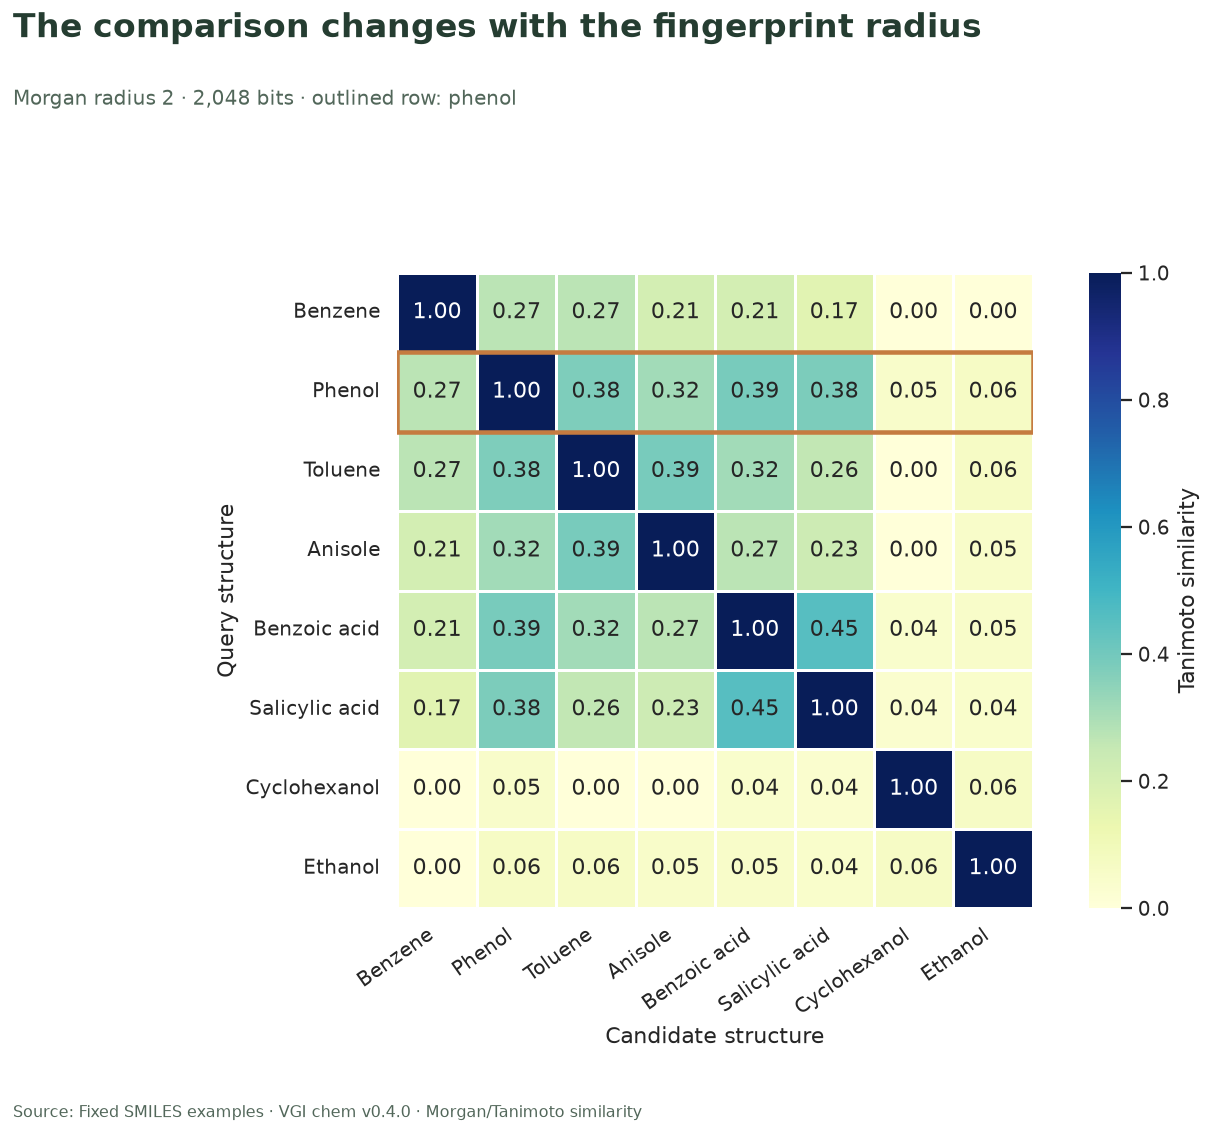

In [13]:
matrix_rows = globals()["matrix_rows"]
ids = library.molecule_id.tolist()
names = library.name.tolist()
matrix = matrix_rows.pivot(index="left_id", columns="right_id", values="worker_score").loc[ids, ids]
fig, ax = plt.subplots(figsize=(10.6, 8.9))
sns.heatmap(
    matrix,
    vmin=0,
    vmax=1,
    cmap="YlGnBu",
    annot=True,
    fmt=".2f",
    linewidths=0.6,
    linecolor="white",
    square=True,
    xticklabels=names,
    yticklabels=names,
    cbar_kws={"label": "Tanimoto similarity"},
    ax=ax,
)
query_row = names.index("Phenol")
ax.add_patch(
    Rectangle((0, query_row), len(names), 1, fill=False, edgecolor="#c57b40", linewidth=2.5)
)
ax.set(xlabel="Candidate structure", ylabel="Query structure")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
finish(
    fig,
    "The comparison changes with the fingerprint radius",
    f"Morgan radius {MORGAN_RADIUS} · 2,048 bits · outlined row: phenol",
    f"matrix-radius-{MORGAN_RADIUS}.png",
)

## Rank candidates, then inspect the separate motif test

We exclude phenol itself and sort the other structures by unrounded similarity,
with name as a deterministic tie-breaker. Bar color shows the fixed SMARTS match.
A nearest fingerprint neighbor need not contain the queried motif; inspect both
columns when the retrieval question includes a substructure requirement.

In [14]:
%%sql ranking <<
SELECT d.name, d.smiles, d.has_motif, p.worker_score AS similarity,
       row_number() OVER (ORDER BY p.worker_score DESC, d.name) AS rank
FROM pair_scores p JOIN descriptors d ON d.molecule_id = p.right_id
WHERE p.left_id = 2 AND p.right_id <> 2 AND p.radius = {{ MORGAN_RADIUS }}
ORDER BY similarity DESC, d.name;

,name,smiles,has_motif,similarity,rank
0,Benzoic acid,O=C(O)c1ccccc1,False,0.388889,1
1,Salicylic acid,O=C(O)c1ccccc1O,True,0.380952,2
2,Toluene,Cc1ccccc1,False,0.375000,3
3,Anisole,COc1ccccc1,False,0.315789,4
4,Benzene,c1ccccc1,False,0.272727,5
5,Ethanol,CCO,False,0.062500,6
6,Cyclohexanol,OC1CCCCC1,False,0.047619,7


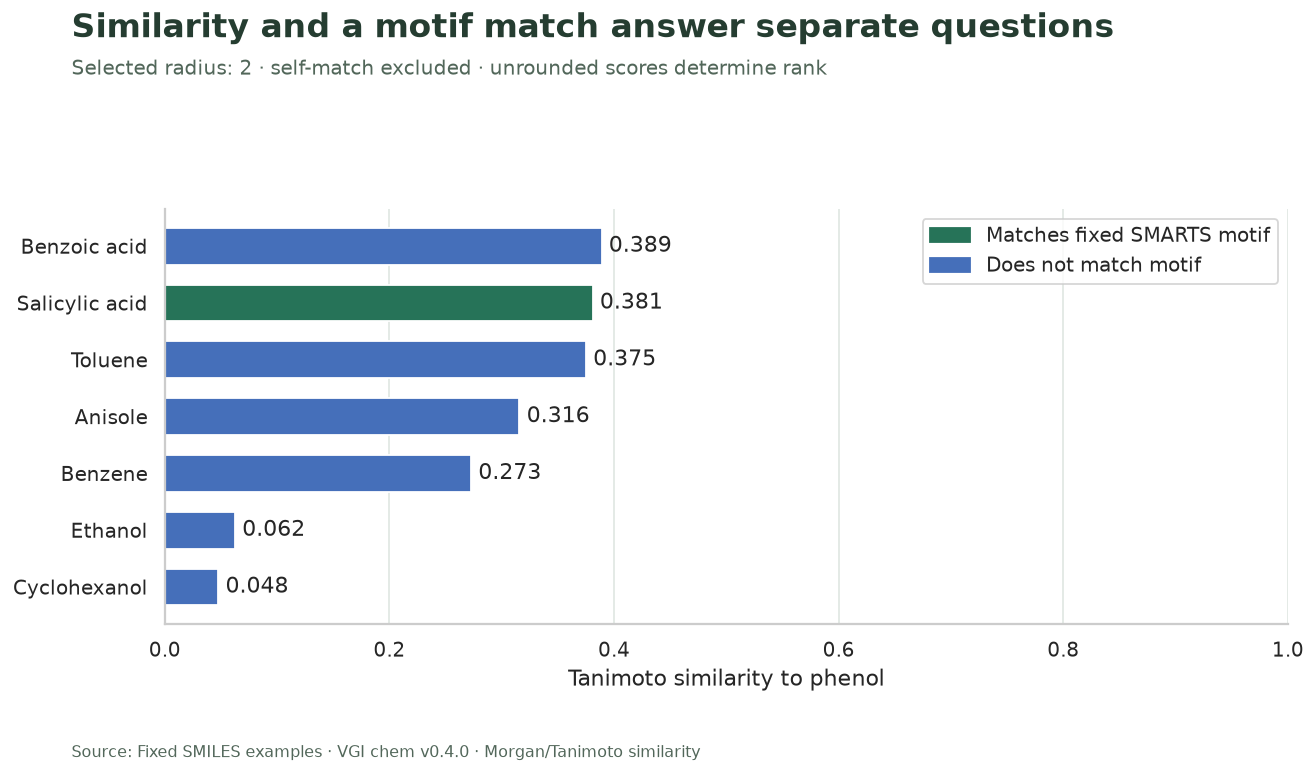

At radius **2**, the nearest candidate is **Benzoic acid**, with similarity **0.389**. It **does not match** the fixed SMARTS motif. The score measures overlapping fingerprint bits; the motif column records an explicit structural query.

In [15]:
ranking = globals()["ranking"]
display(ranking)
y = np.arange(len(ranking))
fig, ax = plt.subplots(figsize=(10.5, 6.0))
bars = ax.barh(
    y,
    ranking.similarity,
    color=["#267358" if match else "#456fba" for match in ranking.has_motif],
    height=0.65,
)
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.set(
    yticks=y,
    yticklabels=ranking.name,
    xlabel="Tanimoto similarity to phenol",
    ylabel="",
    xlim=(0, 1),
)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.legend(
    handles=[
        Patch(color="#267358", label="Matches fixed SMARTS motif"),
        Patch(color="#456fba", label="Does not match motif"),
    ],
    loc="upper right",
    frameon=True,
)
finish(
    fig,
    "Similarity and a motif match answer separate questions",
    f"Selected radius: {MORGAN_RADIUS} · self-match excluded · unrounded scores determine rank",
    f"ranking-radius-{MORGAN_RADIUS}.png",
)
top = ranking.iloc[0]
prose(
    f"At radius **{MORGAN_RADIUS}**, the nearest candidate is **{top['name']}**, with similarity **{top.similarity:.3f}**. It **{'matches' if top.has_motif else 'does not match'}** the fixed SMARTS motif. The score measures overlapping fingerprint bits; the motif column records an explicit structural query."
)

## Compare the two radius settings on the same inputs

The reference table shows both rankings and their score differences. Molecular
identity, formula, molecular weight, TPSA and the fixed SMARTS answer are held
constant; only the fingerprint's radius changes.

In [16]:
%%sql comparison <<
WITH ranked AS (
 SELECT radius, right_id, right_name, worker_score,
        row_number() OVER (PARTITION BY radius ORDER BY worker_score DESC, right_name) AS rank
 FROM pair_scores WHERE left_id = 2 AND right_id <> 2
)
SELECT a.right_name AS name, a.worker_score AS radius_2_score, b.worker_score AS radius_3_score,
       a.rank AS radius_2_rank, b.rank AS radius_3_rank
FROM ranked a JOIN ranked b USING(right_id) WHERE a.radius = 2 AND b.radius = 3
ORDER BY a.rank;

In [17]:
comparison = globals()["comparison"]
display(comparison)
changed = int((comparison.radius_2_rank != comparison.radius_3_rank).sum())
prose(
    f"Changing radius moves **{changed} of {len(comparison)} candidates** to a different rank in this library. Compare the exact score columns before interpreting a small gap; neither radius is established as universally better by these examples."
)

,name,radius_2_score,radius_3_score,radius_2_rank,radius_3_rank
0,Benzoic acid,0.388889,0.363636,1,2
1,Salicylic acid,0.380952,0.296296,2,4
2,Toluene,0.375000,0.368421,3,1
3,Anisole,0.315789,0.304348,4,3
4,Benzene,0.272727,0.214286,5,5
5,Ethanol,0.062500,0.055556,6,6
6,Cyclohexanol,0.047619,0.040000,7,7


Changing radius moves **4 of 7 candidates** to a different rank in this library. Compare the exact score columns before interpreting a small gap; neither radius is established as universally better by these examples.

## Experiment: grow the fingerprint radius

Set **`MORGAN_RADIUS = 3`**, restart and run all. Predict which candidate will
lead and whether the SMARTS-positive candidate will move. Compare the matrix,
ranked bars and nearest-neighbor interpretation. The input-quality table,
canonical library, descriptors, SMARTS results and full two-radius reference
comparison should stay unchanged. Reset to **2**.

Keep fingerprint settings and structure preparation alongside any saved scores.
These examples use a fixed 2,048-bit Morgan representation and a small neutral
molecule library; a similarity score describes that representation and should
be evaluated against the retrieval task you actually need.

In [18]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)